# ML Lab 2 – Activities 1, 2 & 3

---
## Activity 1 – Predict Medical Insurance Cost (Linear Regression)

**Dataset:** `Medical_Cost_Personal_Datasets.csv`
**Features:** age, bmi, children, smoker, region
**Target:** charges

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load and explore the dataset
data1 = pd.read_csv("Medical_Cost_Personal_Datasets.csv")
print(data1.shape)
data1.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
data1.info()
data1.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [3]:
# 2. Preprocess
# Encode categorical features: region, smoker (sex is not used, per the activity's feature list)
le_smoker = LabelEncoder()
le_region = LabelEncoder()
data1['smoker'] = le_smoker.fit_transform(data1['smoker'])   # yes=1, no=0
data1['region'] = le_region.fit_transform(data1['region'])

X1 = data1[['age', 'bmi', 'children', 'smoker', 'region']]
y1 = data1['charges']

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42)

scaler1 = StandardScaler()
X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled = scaler1.transform(X1_test)

In [4]:
# 3. Train a Linear Regression model
lr1 = LinearRegression()
lr1.fit(X1_train_scaled, y1_train)

# 4. Evaluate using RMSE & R2 score
y1_pred = lr1.predict(X1_test_scaled)

rmse1 = np.sqrt(mean_squared_error(y1_test, y1_pred))
r2_1 = r2_score(y1_test, y1_pred)
print("RMSE:", rmse1)
print("R2 score:", r2_1)

RMSE: 5800.056649417455
R2 score: 0.7833112270019789


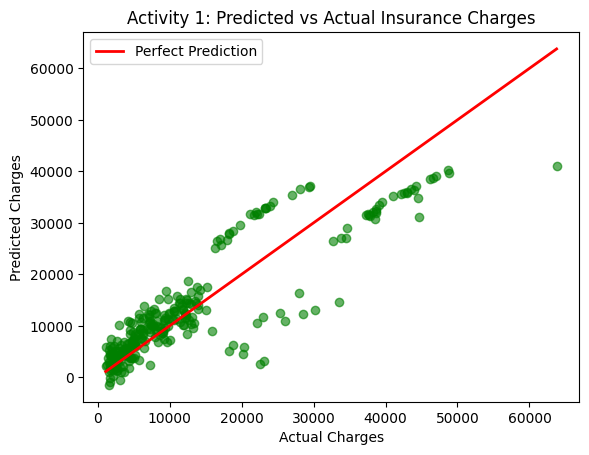

In [5]:
# 5. Plot Predicted vs Actual Costs
plt.scatter(y1_test, y1_pred, color='green', alpha=0.6)
plt.plot([y1.min(), y1.max()], [y1.min(), y1.max()], color='red', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Activity 1: Predicted vs Actual Insurance Charges')
plt.legend()
plt.show()

---
## Activity 2 – Predict Customer Churn (Logistic Regression)

**Dataset:** `Telco_Customer_Churn.csv`
**Features:** tenure, MonthlyCharges, Contract, InternetService
**Target:** Churn

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score

# 1. Load dataset and preprocess categorical variables (Encoding)
data2 = pd.read_csv("Telco_Customer_Churn.csv")
print(data2.shape)
data2.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
le_contract = LabelEncoder()
le_internet = LabelEncoder()
le_churn = LabelEncoder()

data2['Contract'] = le_contract.fit_transform(data2['Contract'])
data2['InternetService'] = le_internet.fit_transform(data2['InternetService'])
data2['Churn'] = le_churn.fit_transform(data2['Churn'])   # Yes=1, No=0

X2 = data2[['tenure', 'MonthlyCharges', 'Contract', 'InternetService']]
y2 = data2['Churn']

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

In [8]:
# 2. Train a Logistic Regression model
log_model = LogisticRegression()
log_model.fit(X2_train_scaled, y2_train)

y2_pred = log_model.predict(X2_test_scaled)
y2_proba = log_model.predict_proba(X2_test_scaled)[:, 1]

In [9]:
# 3. Evaluate using Accuracy, Precision, Recall, F1-score
print("Accuracy: ", accuracy_score(y2_test, y2_pred))
print("Precision:", precision_score(y2_test, y2_pred))
print("Recall:   ", recall_score(y2_test, y2_pred))
print("F1-score: ", f1_score(y2_test, y2_pred))

Accuracy: 

 0.8041163946061036
Precision: 0.6600660066006601
Recall:    0.5361930294906166
F1-score:  0.591715976331361


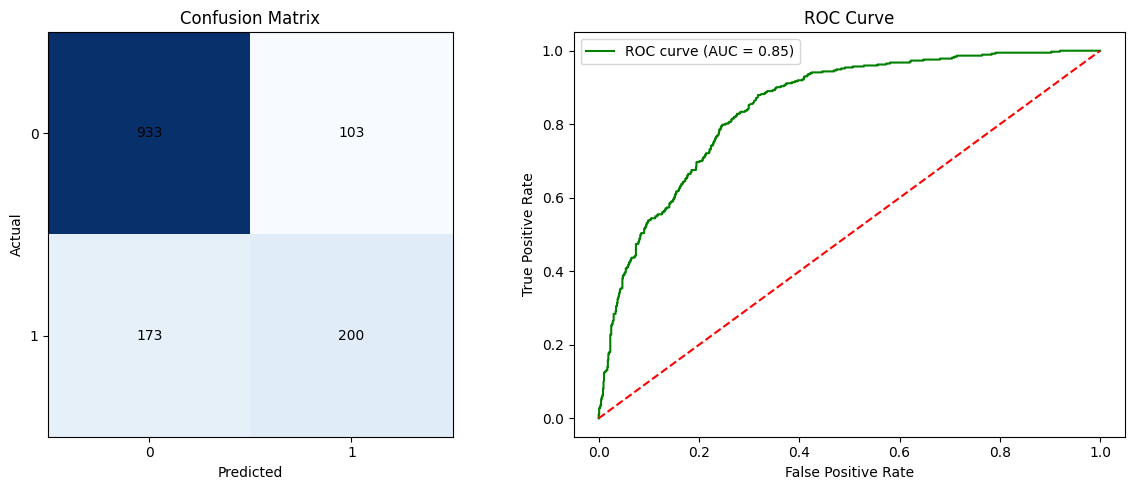

In [10]:
# 4. Plot Confusion Matrix & ROC Curve
cm = confusion_matrix(y2_test, y2_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', color='black')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])

fpr, tpr, _ = roc_curve(y2_test, y2_proba)
auc = roc_auc_score(y2_test, y2_proba)
axes[1].plot(fpr, tpr, color='green', label=f'ROC curve (AUC = {auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Activity 3 – Predict Used Car Prices (Linear & Polynomial Regression)

**Dataset:** `Car_Price_Prediction.csv`

**Note on the dataset:** the activity asks for `Kms_Driven`, `Year`, `Engine`, and `Horsepower`, but this CSV does not contain a mileage or year column (it lists car specs instead: engine size, horsepower, curb weight, mpg, etc.). The closest available numeric features are used instead: **horsepower, enginesize, curbweight, citympg**. Tell your teacher about this substitution if she asks.

In [11]:
from sklearn.preprocessing import PolynomialFeatures

# 1. Choose features
data3 = pd.read_csv("Car_Price_Prediction.csv")
print(data3.shape)
data3.head()

(205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [12]:
features3 = ['horsepower', 'enginesize', 'curbweight', 'citympg']
X3 = data3[features3]
y3 = data3['price']

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42)

In [13]:
# 2. Apply Linear Regression and record performance
lin3 = LinearRegression()
lin3.fit(X3_train, y3_train)
y3_pred_lin = lin3.predict(X3_test)

print("Linear Regression:")
print("  RMSE:", np.sqrt(mean_squared_error(y3_test, y3_pred_lin)))
print("  R2:  ", r2_score(y3_test, y3_pred_lin))

Linear Regression:
  RMSE: 3814.8141321939174
  R2:   0.8156566298368468


In [14]:
# 3. Apply Polynomial Regression (degree=2,3,4) and compare results
results = {}
for d in [2, 3, 4]:
    poly3 = PolynomialFeatures(degree=d)
    X3_train_poly = poly3.fit_transform(X3_train)
    X3_test_poly = poly3.transform(X3_test)

    poly_model3 = LinearRegression()
    poly_model3.fit(X3_train_poly, y3_train)
    y3_pred_poly = poly_model3.predict(X3_test_poly)

    rmse = np.sqrt(mean_squared_error(y3_test, y3_pred_poly))
    r2 = r2_score(y3_test, y3_pred_poly)
    results[d] = (rmse, r2)
    print(f"Degree {d}: RMSE = {rmse:.2f}, R2 = {r2:.4f}")

Degree 2: RMSE = 3839.97, R2 = 0.8132
Degree 3: RMSE = 3963.37, R2 = 0.8010
Degree 4: RMSE = 9619.89, R2 = -0.1723


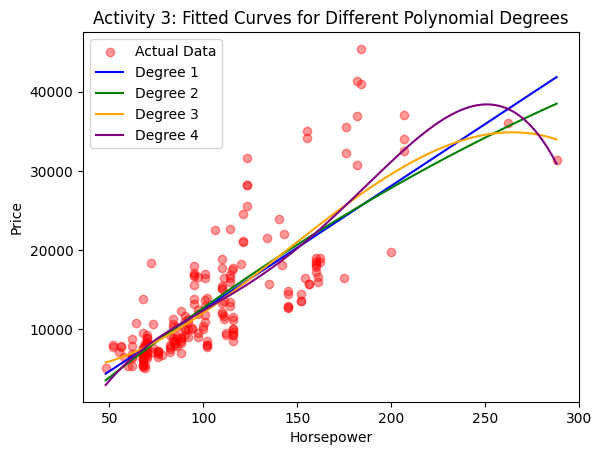

In [15]:
# 4. Plot fitted curves for different polynomial degrees
# Using 'horsepower' alone (single feature) so the curve can be visualised in 2D
Xh = data3[['horsepower']]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, y3, test_size=0.2, random_state=42)

x_grid = pd.DataFrame(np.linspace(Xh['horsepower'].min(), Xh['horsepower'].max(), 200), columns=['horsepower'])

plt.scatter(Xh, y3, color='red', alpha=0.4, label='Actual Data')
for d, color in zip([1, 2, 3, 4], ['blue', 'green', 'orange', 'purple']):
    p = PolynomialFeatures(degree=d)
    Xh_poly = p.fit_transform(Xh_train)
    m = LinearRegression().fit(Xh_poly, yh_train)
    plt.plot(x_grid, m.predict(p.transform(x_grid)), color=color, label=f'Degree {d}')

plt.xlabel('Horsepower')
plt.ylabel('Price')
plt.title('Activity 3: Fitted Curves for Different Polynomial Degrees')
plt.legend()
plt.show()